# Тема 5. Законы распределения дискретных случайных величин
## Задание
Привести примеры (сформулировать условие задачи, нельзя брать задачи из лекций и рассмотренные на практике из учебника) дискретных случайных величин, распределенных по: 
- биномиальному закону распределения; 
- закону распределения Пуассона;
- геометрическому закону распределения;
- гипергеометрическому закону распределения.
Для каждой ДСВ составить закон распределения, найти математическое ожидание, дисперсию, среднее квадратическое отклонение и моду, отобразить многоугольник распределения.

**Импорт библиотек**

In [17]:
import numpy as np
from scipy.stats import binom, poisson, geom, hypergeom
import pandas as pd
import matplotlib.pyplot as plt

np.set_printoptions(formatter={'float_kind': '{:0.4f}'.format})
pd.options.display.float_format = '{:,.4f}'.format

### Операция «Украсть Луну»
### Дело № 543
В секретной организации "Р." наступили непростые времена. Последние несколько лет сотрудники занимались разработкой малозначительных космических проектов, а руководство все чаще задавалось вопросом о целесообразности существования организации.

Ситуация требовала радикальных решений. На очередном совещании директор предложил проект, способный обеспечить организации мировую известность.

План был прост: украсть Луну.

После недолгих обсуждений проект утвердили. Операции присвоили название "Луна навынос", а подготовку поручили **4 подразделениям** организации.

Для выполнения операции была сформирована команда из четырёх специалистов:
- инженер A., который отвечает за ракету;
- диспетчер B., который следит за безопасностью;
- агент C., которому поручено проникнуть на космическую станцию;
- кладовщик D., который собирает оборудование.


### Надёжность оборудования (Биномиальное распределение)

Перед запуском необходимо проверить оборудование

> Для проведения операции «Луна навынос» инженер A. подготовил $10$ независимых систем ракеты. Вероятность того, что каждая система успешно пройдёт проверку, составляет $0.8$. Системы проверяются независимо друг от друга. Найти вероятность того, что не менее $7$ систем успешно пройдут проверку.

>Случайная величина $X$ — число систем, успешно прошедших проверку.

**Теоретический расчет:**
Данная случайная величина имеет биномиальное распределение с параметрами $n = 10$ и $p = 0.8$ (вероятность отказа $q = 1 - p = 0.2$).

*   **Закон распределения (формула Бернулли):** $P(X = k) = C_{10}^k \cdot 0.8^k \cdot 0.2^{10-k}$, где $k \in \{0, 1, ..., 10\}$.
*   **Математическое ожидание:** $M(X) = np = 10 \cdot 0.8 = 8$.
*   **Дисперсия:** $D(X) = npq = 10 \cdot 0.8 \cdot 0.2 = 1.6$.
*   **Среднее квадратическое отклонение:** $\sigma(X) = \sqrt{D(X)} = \sqrt{1.6} \approx 1.265$.
*   **Мода:** Определяется из двойного неравенства $np - q \le Mo(X) \le np + p$.
  
    $8 - 0.2 \le Mo(X) \le 8 + 0.8 \implies 7.8 \le Mo(X) \le 8.8$.

    Следовательно, $Mo(X) = 8$.

In [30]:
n, p = 10, 0.8
X = np.arange(0, n + 1)
binomial_dist = binom(n, p) 
probabilities = binomial_dist.pmf(X)

df = pd.DataFrame(data=probabilities.reshape(1, -1),
                  columns=X,
                  index=['p'])
df.round(4)

,0,1,2,3,4,5,6,7,8,9,10
p,0.0000,0.0000,0.0001,0.0008,0.0055,0.0264,0.0881,0.2013,0.3020,0.2684,0.1074


In [46]:
print(f"Математическое ожидание: {binom.mean(n, p)}")
print(f"Дисперсия: {binom.var(n, p):.2f}")
print(f"Среднее квадратическое отклонение: {binom.std(n, p):.3f}")

max_prob = probabilities.max()
mode = [int(x) for x in X if round(probabilities[x], 6) == round(max_prob, 6)]
print(f'Мода = {mode}')

print(f'P(X <= 3) = {binomial_dist.cdf(3):.4f}')

Математическое ожидание: 8.0
Дисперсия: 1.60
Среднее квадратическое отклонение: 1.265
Мода = [3, 4]
P(X <= 3) = 0.0009


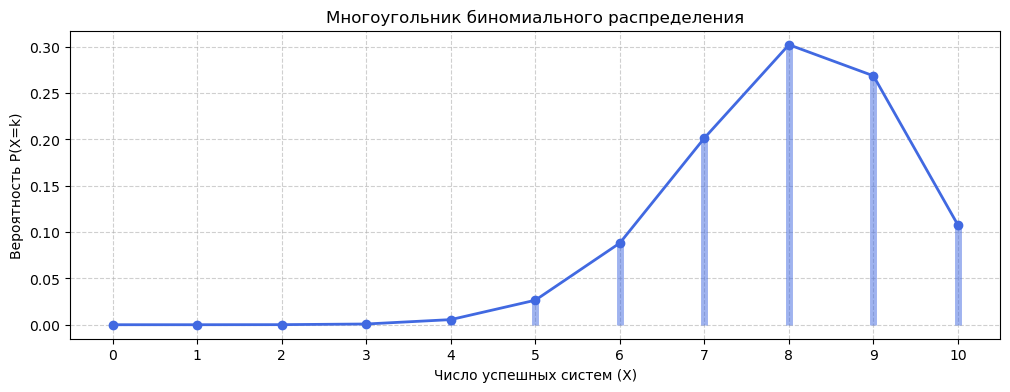

In [60]:
plt.figure(figsize=(12, 4))
plt.plot(x, y, marker='o', color='royalblue', linestyle='-', lw=2)
plt.vlines(x, 0, y, colors='royalblue', lw=5, alpha=0.5)
plt.title('Многоугольник биномиального распределения')
plt.xlabel('Число успешных систем (X)')
plt.ylabel('Вероятность P(X=k)')
plt.xticks(x)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

### Космическая тревога (Распределение Пуассона)

Во время подготовки к запуску организация диспетчер B. сталкивается с неожиданными сигналами тревоги. 

>На секретную базу в среднем поступает 4 ложных сигнала тревоги за день. Предполагается, что сигналы возникают независимо и с постоянной средней интенсивностью. Найти вероятность того, что на базу за один день поступит не менее 2 сигналов тревоги.

>Случайная величина $Y$ — число ложных сигналов тревоги за один день.

**Теоретический расчет:**
Случайная величина распределена по закону Пуассона с параметром интенсивности $\lambda = 4$.

*   **Закон распределения:** $P(Y = m) = \frac{\lambda^m}{m!} e^{-\lambda} = \frac{4^m}{m!} e^{-4}$, где $m \in \{0, 1, 2, ...\}$.
*   **Математическое ожидание:** $M(Y) = \lambda = 4$.
*   **Дисперсия:** $D(Y) = \lambda = 4$.
*   **Среднее квадратическое отклонение:** $\sigma(Y) = \sqrt{\lambda} = \sqrt{4} = 2$.
*   **Мода:** Определяется из неравенства $\lambda - 1 \le Mo(Y) \le \lambda$.
    $3 \le Mo(Y) \le 4$.

    Распределение имеет две моды: $Mo(Y)_1 = 3$ и $Mo(Y)_2 = 4$.

In [48]:
lam = 4
X = np.arange(0, 16) 
probabilities = poisson.pmf(X, lam)

df = pd.DataFrame(data=probabilities.reshape(1, -1),
                  columns=X,
                  index=['p'])
df.round(4)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
p,0.0183,0.0733,0.1465,0.1954,0.1954,0.1563,0.1042,0.0595,0.0298,0.0132,0.0053,0.0019,0.0006,0.0002,0.0001,0.0000


In [49]:
print("\nРаспределение Пуассона")
print(f"Математическое ожидание: {poisson.mean(lam)}")
print(f"Дисперсия: {poisson.var(lam)}")
print(f"Среднее квадратическое отклонение: {poisson.std(lam):.4f}")

max_prob = probabilities.max()
mode = [int(x) for x in X if round(probabilities[x], 4) == round(max_prob, 4)]
print(f'Мода = {mode}')

print(f'P(X >= 2) = {1 - poisson.cdf(1, lam):.4f}')


Распределение Пуассона
Математическое ожидание: 4.0
Дисперсия: 4.0
Среднее квадратическое отклонение: 2.0000
Мода = [3, 4]
P(X >= 2) = 0.9084


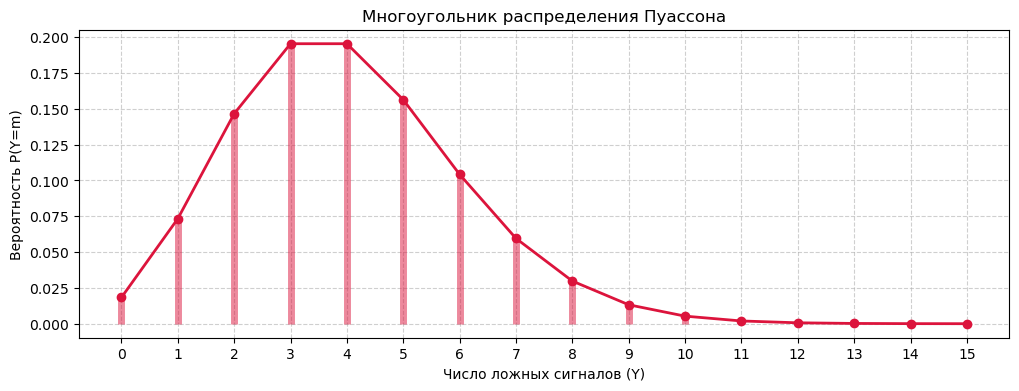

In [59]:
x_pois = X
y_pois = poisson.pmf(X, lam)
plt.figure(figsize=(12, 4))
plt.plot(x_pois, y_pois, marker='o', color='crimson', linestyle='-', lw=2)
plt.vlines(x_pois, 0, y_pois, colors='crimson', lw=5, alpha=0.5)
plt.title('Многоугольник распределения Пуассона')
plt.xlabel('Число ложных сигналов (Y)')
plt.ylabel('Вероятность P(Y=m)')
plt.xticks(x_pois)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

### Агент-"ниндзя" (Геометрическое распределение)

Агент C. должен проникнуть на космическую станцию, чтобы получить доступ к управлению спутником

> Вероятность того, что одна попытка проникновения окажется успешной, составляет $0.25$. Попытки независимы. Найти вероятность того, что для успешного проникновения понадобится не менее $7$ попыток.

>Случайная величина $Z$ — номер первой успешной попытки проникновения.

**Теоретический расчет:**
Случайная величина имеет геометрическое распределение (число испытаний до первого успеха).

*   **Закон распределения:** $P(Z = k) = p \cdot q^{k-1} = 0.25 \cdot 0.75^{k-1}$, где $k \in \{1, 2, 3, ...\}$.
*   **Математическое ожидание:** $M(Z) = \frac{1}{p} = \frac{1}{0.25} = 4$.
*   **Дисперсия:** $D(Z) = \frac{q}{p^2} = \frac{0.75}{0.25^2} = 12$.
*   **Среднее квадратическое отклонение:** $\sigma(Z) = \sqrt{12} \approx 3.4641$.
*   **Мода:** В геометрическом распределении вероятность монотонно убывает с ростом $k$, поэтому наивероятнейшим всегда является первый исход: $Mo(Z) = 1$.

In [56]:
p_geom = 0.25
x_geom = np.arange(1, 16)
y_geom = geom.pmf(x_geom, p_geom)

df = pd.DataFrame(
    data=y_geom.reshape(1, -1),
    columns=x_geom,
    index=['p'])

df.round(4)

,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
p,0.2500,0.1875,0.1406,0.1055,0.0791,0.0593,0.0445,0.0334,0.0250,0.0188,0.0141,0.0106,0.0079,0.0059,0.0045


In [44]:
print("Геометрическое распределение")
print(f"Математическое ожидание: {geom.mean(p_geom)}")
print(f"Дисперсия: {geom.var(p_geom)}")
print(f"Среднее квадратическое отклонение: {geom.std(p_geom):.4f}")

mode = int(geom.ppf(1 - p_geom, p_geom))
print(f"Мода = {mode}")

P = geom.sf(5, p_geom)
print(f"P(X >= 7) = {P:.4f}")

Геометрическое распределение
Математическое ожидание: 4.0
Дисперсия: 12.0
Среднее квадратическое отклонение: 3.4641
Мода = 5
P(X >= 7) = 0.2373


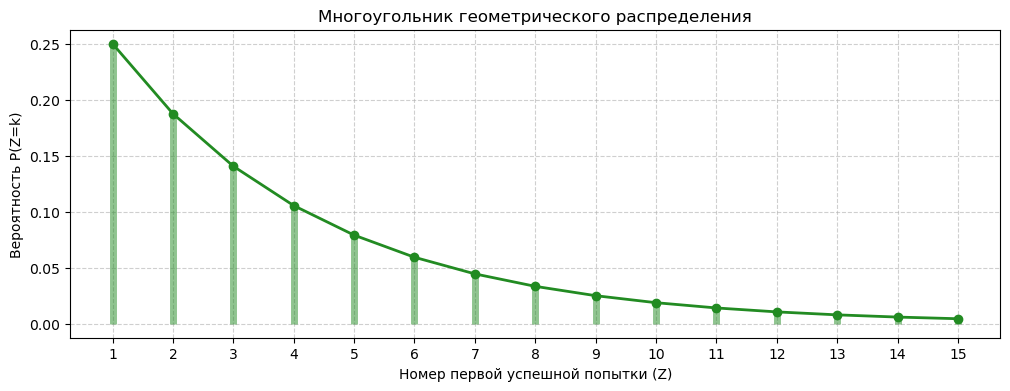

In [58]:
plt.figure(figsize=(12, 4))
plt.plot(x_geom, y_geom, marker='o', color='forestgreen', linestyle='-', lw=2)
plt.vlines(x_geom, 0, y_geom, colors='forestgreen', lw=5, alpha=0.5)
plt.title('Многоугольник геометрического распределения')
plt.xlabel('Номер первой успешной попытки (Z)')
plt.ylabel('Вероятность P(Z=k)')
plt.xticks(x_geom)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

### Комплектация миссии (Гипергеометрическое распределение)

Перед запуском нужно кладовщик D. выбирает оборудование из общего запаса 

> На складе организации находится $20$ устройств, из которых $13$ являются специальными модулями, необходимыми для управления захватом Луны. Для проведения операции случайным образом отбирают $7$ устройств без возвращения. Найти вероятность, что среди них окажется 5 специальных модулей.

> Случайная величина $W$ — число специальных модулей среди отобранных устройств.

**Теоретический расчет:**
Случайная величина распределена по гипергеометрическому закону.
Параметры: $N = 20$ (всего на складе), $M = 13$ (специальные модули), $n = 7$ (отбираемые устройства), $m=5$ (специальные модули).

*   **Закон распределения:** $P(W = m) = \frac{C_M^m \cdot C_{N-M}^{n-m}}{C_N^n} = \frac{C_13^m \cdot C_{7}^{7-m}}{C_{20}^7}$, где $m \in \{0, 1, 2, 3, 4, 5, 6, 7\}$.
*   **Математическое ожидание:** $M(W) = n \frac{M}{N} = 7 \cdot \frac{13}{20} = 4.55$.
*   **Дисперсия:** $D(W) = n \frac{M}{N} \left(1 - \frac{M}{N}\right) \frac{N - n}{N - 1} = 7 \cdot \frac{13}{20} \cdot \frac{7}{20} \cdot \frac{13}{19} = \frac{8281}{7600} \approx 1.0896$.
*   **Среднее квадратическое отклонение:** $\sigma(W) = \sqrt{D(W)} \approx 1.0438$.
*   **Мода:** Определяется из неравенства $\frac{(n+1)(M+1)}{N+2} - 1 \le Mo(W) \le \frac{(n+1)(M+1)}{N+2}$.
  
    $\frac{(7+1) \cdot (13+1)}{20+2} - 1 \le Mo(W) \le \frac{(7+1) \cdot (13+1)}{20+2}.  \implies 1.18 \le Mo(W) \le 2.18$. Значит, $Mo(W) = 2$.

In [62]:
N_total, M_succ, n_draw = 20, 13, 7
x_hyp = np.arange(0, n_draw + 1)
y_hyp = hypergeom.pmf(x_hyp, N_total, M_succ, n_draw)

df = pd.DataFrame(
    data=y_hyp.reshape(1, -1),
    columns=x_hyp,
    index=['p']
)

df.round(4)

,0,1,2,3,4,5,6,7
p,0.0000,0.0012,0.0211,0.1291,0.3228,0.3486,0.1550,0.0221


In [69]:
print("Гипергеометрическое распределение")
print(f"Математическое ожидание: {hypergeom.mean(N_total, M_succ, n_draw)}")
print(f"Дисперсия: {hypergeom.var(N_total, M_succ, n_draw):.4f}")
print(f"Среднее квадратическое отклонение: {hypergeom.std(N_total, M_succ, n_draw):.4f}")

mode = int(np.argmax(y_hyp))
print(f"Мода = {mode}")

P = hypergeom.pmf(5, N_total, M_succ, n_draw)
print(f"P(m = 5) = {P:.4f}")

Гипергеометрическое распределение
Математическое ожидание: 4.55
Дисперсия: 1.0896
Среднее квадратическое отклонение: 1.0438
Мода = 5
P(m = 5) = 0.3486


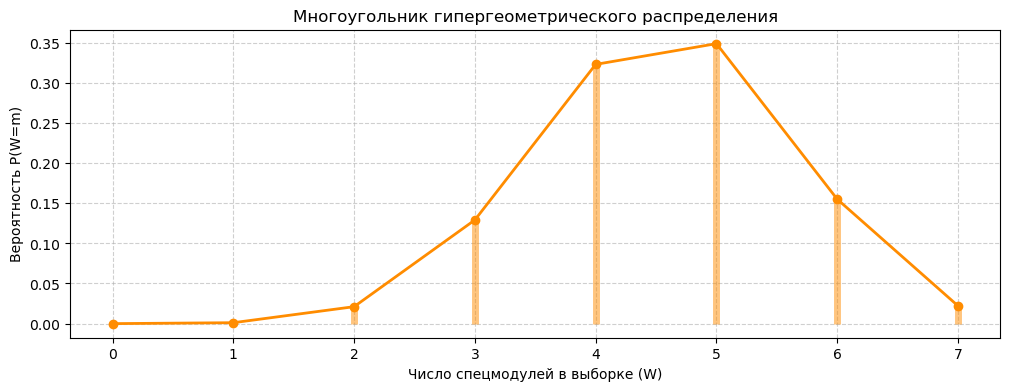

In [66]:
plt.figure(figsize=(12, 4))
plt.plot(x_hyp, y_hyp, marker='o', color='darkorange', linestyle='-', lw=2)
plt.vlines(x_hyp, 0, y_hyp, colors='darkorange', lw=5, alpha=0.5)
plt.title('Многоугольник гипергеометрического распределения')
plt.xlabel('Число спецмодулей в выборке (W)')
plt.ylabel('Вероятность P(W=m)')
plt.xticks(x_hyp)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()